# Practical Session 4.3: Advanced Statistics Course, Brain science
## Mixed-design ANOVA and mixed-effects models

Welcome to the third Week 4 practice notebook!
Here we combine a **within-subject** factor (measurement session) with a **between-subject** factor (training group) in a **mixed-design ANOVA**. We work out the df of a mixed design by hand, check the assumptions of both factor types (**Levene** and **Mauchly**), follow up the interaction, and finally compare the ANOVA with a **linear mixed-effects model**, the robust alternative mentioned in the lecture.

Each exercise cell is followed by a **✅ Solution** cell. Try the exercise first before looking at the solution.

### Paper-and-pencil questions: Mixed-design ANOVA

#### Question 1

A study compares **three** groups of participants (between factor *Group*) on a perceptual task measured at **four** sessions (within factor *Session*). The between-subjects effect is reported as $F(2,27)$.

Some sums of squares from the output:

| Source | SS |
|---|---:|
| Group | 40 |
| Error (between) | 270 |
| Session | 36 |
| Group × Session | 18 |
| Error (within) | 162 |

1. How many groups and how many participants are there in total? Explain how you get this from $F(2,27)$.
2. Give the df for Session, Group × Session and the within-subjects error.
3. Compute all MS and F-values. Use $F_{crit}(2,27)=3.35$, $F_{crit}(3,81)=2.72$, $F_{crit}(6,81)=2.21$. Which effects are significant?
4. Compute partial $\eta^2$ for each effect.
5. Which F-ratios use the between-subjects error term and which use the within-subjects error term? Why?
6. Which effects require a sphericity check and which require Levene's test?

### Answer

#### Question 1

1. Between effect df $=g-1=2$ → $g=3$ groups. Between error df $=n-g=27$ → $n=30$ participants (10 per group if balanced).

2. With $k=4$ sessions:

   | Effect | df |
   |---|---:|
   | Session | $k-1=3$ |
   | Group × Session | $(g-1)(k-1)=2\cdot3=6$ |
   | Error (within) | $(k-1)(n-g)=3\cdot27=81$ |

3. **MS and F**

   | Source | SS | df | MS | F | Significant? |
   |---|---:|---:|---:|---:|---|
   | Group | 40 | 2 | 20 | $20/10=2.00$ | No ($<3.35$, $p\approx.15$) |
   | Error (between) | 270 | 27 | 10 | | |
   | Session | 36 | 3 | 12 | $12/2=6.00$ | Yes ($>2.72$, $p\approx.001$) |
   | Group × Session | 18 | 6 | 3 | $3/2=1.50$ | No ($<2.21$, $p\approx.19$) |
   | Error (within) | 162 | 81 | 2 | | |

4. **Partial $\eta^2$**

   - Group: $40/(40+270)=.13$
   - Session: $36/(36+162)=.18$
   - Group × Session: $18/(18+162)=.10$

5. **Group** is tested against the **between-subjects** error (variation between participants within groups): it compares participants' overall means. **Session** and **Group × Session** are tested against the **within-subjects** error (session × subject residual), because these effects are estimated from changes *within* participants, from which stable individual differences have been removed.

6. **Sphericity (Mauchly):** Session and Group × Session (within effects with 4 > 2 levels). **Levene:** Group (between factor), i.e., equal variances across groups, checked at each session. Mauchly is for within factors only; Levene is for between factors only.

#### Question 2

For each question, select the **best** answer and briefly justify your choice.

---

1. A data file has one row per participant and the columns `ID`, `Group`, `Pre`, `Post`, `FollowUp`. What must be done before running `pg.mixed_anova`?

   A. Nothing, Pingouin accepts this format

   B. Convert it to long format: one row per participant per session (`ID | Group | Session | DV`)

   C. Average Pre, Post and FollowUp per participant

   D. Split the file by group and run two RM-ANOVAs

2. Levene's test for Group at the Post session gives $p=.02$. What does this indicate?

   A. Sphericity is violated

   B. Variances of the DV differ between the groups at Post: the homogeneity-of-variance assumption is violated

   C. The groups differ in their means at Post

   D. The within-subject factor must be corrected with Greenhouse–Geisser

3. Mauchly's test for Session gives $p=.03$ with $\hat\varepsilon_{GG}=0.81$. Which correction is appropriate?

   A. Greenhouse–Geisser, because Mauchly is significant

   B. Huynh–Feldt, because $\hat\varepsilon>0.75$

   C. Lower bound, because it is the safest

   D. No correction, because $\hat\varepsilon$ is close to 1

4. In a pre/post/follow-up training study, the **Group** main effect is not significant but the **Group × Session** interaction is. Which interpretation is most appropriate?

   A. Training has no effect, because the Group effect is not significant

   B. The groups change differently over time; because both groups started at the same level, averaging over sessions can hide group differences at later sessions

   C. The interaction is a Type I error because the main effect is not significant

   D. The groups differ at every session

5. Three participants missed the follow-up session. Which statement is correct?

   A. RM/mixed ANOVA uses all of their remaining data

   B. RM/mixed ANOVA drops these participants completely (listwise deletion); a mixed-effects model can still use their Pre and Post data

   C. Mixed-effects models cannot handle missing data

   D. Missing data only matter for the between factor

#### Answer Question 2

1. **Correct answer: B**

   Pingouin (like most ANOVA software in Python) needs **long format**, with one row per participant per level of the within factor. Use `pd.melt`.

2. **Correct answer: B**

   Levene's $H_0$: equal variances across groups. $p<.05$ → homogeneity of variance violated for the between factor. Levene says nothing about sphericity (A, D) or means (C).

3. **Correct answer: B**

   Sphericity is violated ($p<.05$), and $\hat\varepsilon=0.81>0.75$ → **Huynh–Feldt** (GG would be overly conservative here).

4. **Correct answer: B**

   The Group main effect averages over all sessions, including the Pre session where the groups are equal by design. This dilutes the group difference. The interaction shows that the groups **change differently**; simple-effects / post hoc tests per session show where they differ.

5. **Correct answer: B**

   RM-ANOVA needs complete data for every participant, so participants with any missing cell are dropped. Mixed-effects models handle multiple observations per participant individually and keep all available observations.

### Perceptual Learning Experiment: Contrast Sensitivity Training

### Overview
Can perception be trained? Participants' **contrast detection threshold** (the lowest contrast, in %, at which a faint grating can still be detected; **lower = better**) is measured in three sessions:

- **Pre**: before training
- **Post**: after two weeks
- **FollowUp**: one month later

Participants are randomly assigned to one of two groups (**between factor**):

| Group | n | Activity between Pre and Post |
|---|---:|---|
| Training | 14 | daily perceptual-learning training with gratings |
| Control | 14 | daily video game without gratings (same screen time) |

**Research question:** Does perceptual training lower contrast thresholds more than the control activity, and does the improvement last?

### Step 0: Generate the Data

Run the cell below. It simulates the data and saves them as `ContrastTraining_wide.csv` (one row per participant). You don't need to understand this code.

In [1]:
# --- Data simulation: just run this cell ---
import numpy as np
import pandas as pd

rng = np.random.default_rng(41)
means = {"Training": [6.0, 4.6, 4.9], "Control": [6.0, 5.6, 5.8]}
rows, i = [], 1
for g in ["Training", "Control"]:
    for _ in range(14):
        base = rng.normal(0, 0.8)    # individual sensitivity
        vals = [m + base + rng.normal(0, 0.55) for m in means[g]]
        rows.append(dict(ID=f"S{i:02d}", Group=g, Pre=vals[0], Post=vals[1], FollowUp=vals[2]))
        i += 1
pd.DataFrame(rows).round(2).to_csv("ContrastTraining_wide.csv", index=False)
print("Saved ContrastTraining_wide.csv")

Saved ContrastTraining_wide.csv


### Step 1: Load the Data and Identify the Design

Load `ContrastTraining_wide.csv` into `wide` and inspect it.

### Questions
- What is the DV? Which factor is within-subject, which is between-subject?
- Which analysis is appropriate?
- Why can't the data be analysed in this format with Pingouin?

In [ ]:
import pandas as pd

wide = ___

#### ✅ Solution

In [3]:
import pandas as pd

wide = pd.read_csv("ContrastTraining_wide.csv")
print(wide.head())
print("\nParticipants per group:\n", wide["Group"].value_counts())

    ID     Group   Pre  Post  FollowUp
0  S01  Training  5.16  3.61      4.19
1  S02  Training  5.55  3.59      3.19
2  S03  Training  4.19  3.12      4.47
3  S04  Training  6.42  5.02      6.68
4  S05  Training  6.28  5.24      5.39

Participants per group:
 Group
Training    14
Control     14
Name: count, dtype: int64


- **DV:** contrast threshold (%).
- **Session** (Pre, Post, FollowUp) is **within-subject**: every participant is measured three times. **Group** (Training, Control) is **between-subject**: each participant belongs to one group only.
- → **2 (Group) × 3 (Session) mixed-design ANOVA**.
- The file is in **wide format** (one row per participant, one column per session). Pingouin needs **long format**: one row per participant per session.

### Step 2: Reshape to Long Format

Use `pd.melt` to create `long` with the columns `ID | Group | Session | Threshold`. Check that each participant has 3 rows.

In [ ]:
long = ___

#### ✅ Solution

In [5]:
long = wide.melt(id_vars=["ID", "Group"], value_vars=["Pre", "Post", "FollowUp"],
                 var_name="Session", value_name="Threshold")
session_order = ["Pre", "Post", "FollowUp"]

print(long.sort_values(["ID", "Session"]).head(6))
print("\nRows per participant:", long.groupby("ID").size().unique(), "| total rows:", len(long))

     ID     Group   Session  Threshold
56  S01  Training  FollowUp       4.19
28  S01  Training      Post       3.61
0   S01  Training       Pre       5.16
57  S02  Training  FollowUp       3.19
29  S02  Training      Post       3.59
1   S02  Training       Pre       5.55

Rows per participant: [3] | total rows: 84


### Step 3: Descriptives and Interaction Plot

1. Table of mean (and SD) threshold per Group × Session.
2. Interaction plot: Session on the x-axis (in the order Pre, Post, FollowUp), one line per Group, 95% CIs.

### Questions
1. Do the groups differ at Pre?
2. Describe the pattern over sessions for each group. Do you expect a main effect of Group? Of Session? An interaction?

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

# Descriptives
# Write your code here

# Interaction plot
# Write your code here

#### ✅ Solution

          mean                  std               
Session    Pre  Post FollowUp   Pre  Post FollowUp
Group                                             
Control   5.93  5.48     5.69  0.78  0.99     0.82
Training  5.98  4.39     4.84  0.95  0.91     1.13


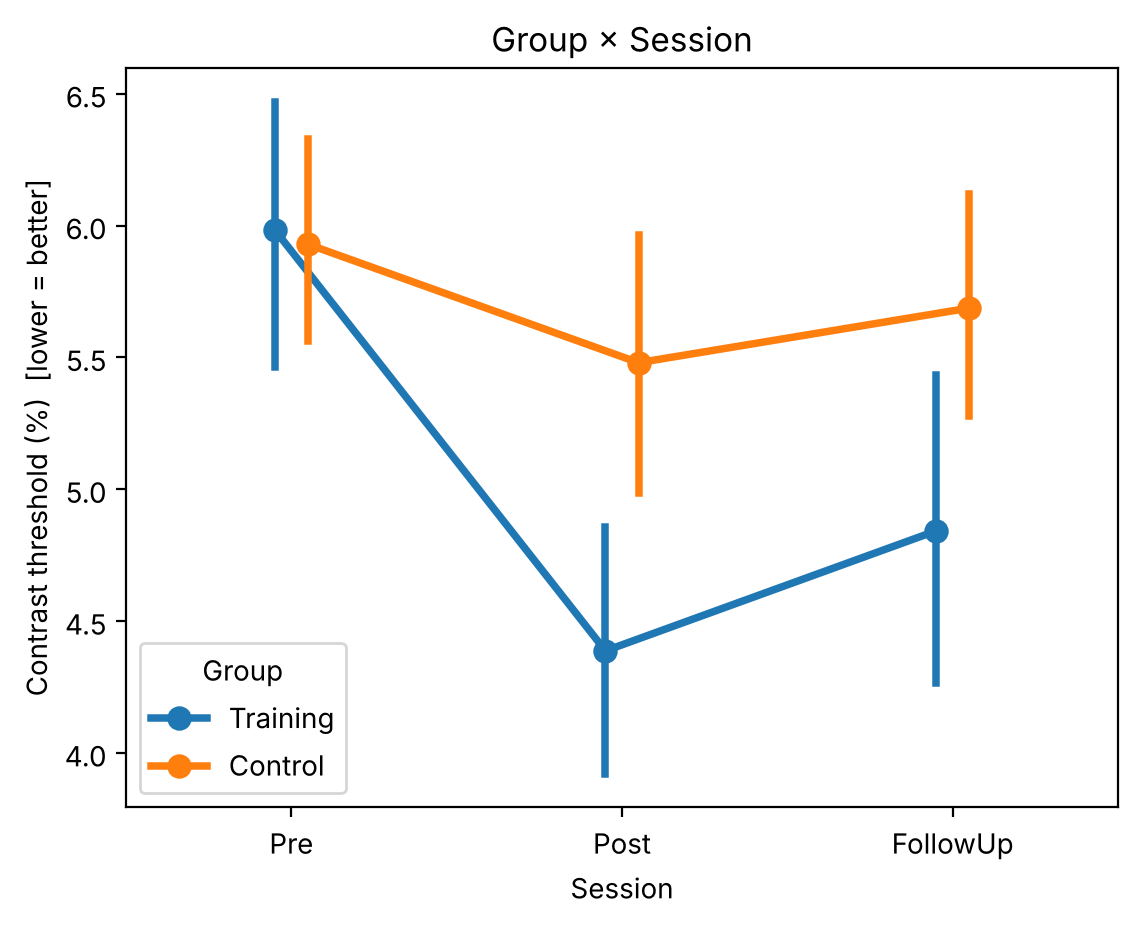

In [7]:
import seaborn as sns
import matplotlib.pyplot as plt

desc = long.groupby(["Group", "Session"])["Threshold"].agg(["mean", "std"]).unstack("Session")
print(desc.reindex(columns=session_order, level=1).round(2))

sns.pointplot(data=long, x="Session", y="Threshold", hue="Group", order=session_order,
              errorbar=("ci", 95), dodge=0.1)
plt.ylabel("Contrast threshold (%)  [lower = better]")
plt.title("Group × Session")
plt.show()

1. At **Pre** both groups have nearly identical thresholds (5.98% vs 5.93%): randomisation worked.
2. **Training:** clear drop from Pre to Post (≈ 6.0 → 4.4%), slightly rising again at FollowUp (4.8%) but still well below Pre. **Control:** only a small drop (5.9 → 5.5 → 5.7%).
   - Session main effect: likely (both groups improve somewhat).
   - Interaction: likely (the training group improves much more → lines diverge after Pre).
   - Group main effect: uncertain. It averages over all three sessions, including Pre where the groups are identical, and the between-subject SDs (≈ 0.8–1.1%) are large relative to the group differences.

### Step 4: Assumptions

1. **Normality:** Shapiro–Wilk for each Group × Session cell.
2. **Homogeneity of variance (between factor):** Levene's test for Group, separately at each session.
3. **Sphericity (within factor):** Mauchly's test for Session.

### Question
Why do we use Levene for one factor and Mauchly for the other?

In [ ]:
import pingouin as pg

# Normality
# Write your code here

# Levene per session
# Write your code here

# Mauchly
# Write your code here

#### ✅ Solution

In [9]:
import pingouin as pg

long["Cell"] = long["Group"] + "_" + long["Session"]
print(pg.normality(data=long, dv="Threshold", group="Cell").round(3))

print("\nLevene (Group) per session:")
for s in session_order:
    lev = pg.homoscedasticity(data=long[long["Session"] == s], dv="Threshold", group="Group")
    print(f"  {s:<8} W = {lev['W'].iloc[0]:.3f}, p = {lev['pval'].iloc[0]:.3f}")

print("\nMauchly (Session):", pg.sphericity(data=long, dv="Threshold", within="Session", subject="ID"))

                       W   pval  normal
Cell                                   
Training_Pre       0.950  0.559    True
Control_Pre        0.965  0.808    True
Training_Post      0.953  0.603    True
Control_Post       0.986  0.996    True
Training_FollowUp  0.949  0.553    True
Control_FollowUp   0.969  0.867    True

Levene (Group) per session:
  Pre      W = 1.545, p = 0.225
  Post     W = 0.020, p = 0.888
  FollowUp W = 1.760, p = 0.196

Mauchly (Session): SpherResults(spher=True, W=np.float64(0.8720362539831756), chi2=np.float64(3.5600312869841755), dof=2, pval=np.float64(0.1686355091997074))


- **Normality:** all Shapiro–Wilk $p>.05$ → acceptable.
- **Levene:** all $p>.05$ → variances do not differ between groups at any session → homogeneity of variance holds.
- **Mauchly:** $p=.17$ → sphericity not violated. (The mixed ANOVA in Step 5 computes Mauchly within the groups and reports $p=.09$; same conclusion.)
- **Why two tests?** Levene compares variances **between groups of different people** (between factor). Sphericity concerns the variances of **difference scores within the same people** (within factor with > 2 levels). Each assumption only exists for its factor type.

### Step 5: Run the Mixed ANOVA

Run `pg.mixed_anova` (with `correction=True`).

### Questions
1. Report F, df, p and partial $\eta^2$ for each effect. Which are significant?
2. Check the df by hand: what do $DF1$/$DF2$ tell you about the number of groups and participants?
3. How can the Group effect be non-significant when the plot shows a clear group difference after training?

In [ ]:
aov = ___
aov

#### ✅ Solution

In [11]:
aov = pg.mixed_anova(data=long, dv="Threshold", within="Session", between="Group",
                     subject="ID", correction=True)
print(aov.round(4).to_string())

g, k, n = long["Group"].nunique(), long["Session"].nunique(), long["ID"].nunique()
print(f"\nBy hand: between df = {g - 1}, between error df = {n - g}, "
      f"within df = {k - 1}, interaction df = {(g - 1) * (k - 1)}, within error df = {(k - 1) * (n - g)}")

        Source       SS  DF1  DF2      MS        F   p_unc  p_GG_corr     np2     eps sphericity  W_spher  p_spher
0        Group   8.2783    1   26  8.2783   3.7529  0.0637        NaN  0.1261     NaN        NaN      NaN      NaN
1      Session  15.2545    2   52  7.6273  35.8957  0.0000     0.0000  0.5799  0.8508       True   0.8246   0.0898
2  Interaction   5.1009    2   52  2.5504  12.0030  0.0001     0.0001  0.3158  0.8508       True   0.8246   0.0898

By hand: between df = 1, between error df = 26, within df = 2, interaction df = 2, within error df = 52


1. Results:
   - **Group:** $F(1,26)=3.75,\ p=.064,\ \eta^2_p=.13$ → **not significant**.
   - **Session:** $F(2,52)=35.90,\ p<.001,\ \eta^2_p=.58$ → significant.
   - **Group × Session:** $F(2,52)=12.00,\ p<.001,\ \eta^2_p=.32$ → significant.
   - Sphericity holds (Mauchly $p=.09$), so uncorrected df are reported.
2. Between df $=g-1=1$ → 2 groups; between error df $=n-g=26$ → 28 participants; within error df $=(k-1)(n-g)=2\cdot26=52$.
3. The Group effect compares the groups' **average over all sessions**, which includes Pre (no difference by design). It is tested against the between-subjects error, which contains the large individual differences in sensitivity. The interaction is tested against the much smaller within-subjects error. → With a significant interaction, interpret the main effects **with caution** and follow up the interaction.

### Step 6: Follow Up the Interaction

Run Bonferroni-corrected post hoc tests with `pg.pairwise_tests(..., within="Session", between="Group", padjust="bonf")`.

### Questions
1. At which sessions do the two groups differ?
2. Within each group, which sessions differ?

In [ ]:
posthoc = ___
posthoc

#### ✅ Solution

In [13]:
posthoc = pg.pairwise_tests(data=long, dv="Threshold", within="Session", between="Group",
                            subject="ID", padjust="bonf", within_first=False)
# within_first=False -> rows = Group, A/B = sessions (session comparisons within each group)
inter = posthoc[posthoc["Contrast"] == "Group * Session"]
print("Session comparisons within each group:")
print(inter[["Group", "A", "B", "T", "dof", "p_unc", "p_corr", "hedges"]].round(4).to_string())

# within_first=True -> rows = Session, A/B = groups (group comparisons at each session)
posthoc2 = pg.pairwise_tests(data=long, dv="Threshold", within="Session", between="Group",
                             subject="ID", padjust="bonf", within_first=True)
inter2 = posthoc2[posthoc2["Contrast"] == "Session * Group"]
print("\nGroup comparisons at each session:")
print(inter2[["Session", "A", "B", "T", "dof", "p_unc", "p_corr", "hedges"]].round(4).to_string())

Session comparisons within each group:
      Group         A     B        T   dof   p_unc  p_corr  hedges
4   Control  FollowUp  Post   1.1560  13.0  0.2685  1.0000  0.2218
5   Control  FollowUp   Pre  -1.3393  13.0  0.2034  1.0000 -0.2938
6   Control      Post   Pre  -3.4018  13.0  0.0047  0.0284 -0.4891
7  Training  FollowUp  Post   2.8340  13.0  0.0141  0.0845  0.4306
8  Training  FollowUp   Pre  -5.0387  13.0  0.0002  0.0014 -1.0643
9  Training      Post   Pre -10.5737  13.0  0.0000  0.0000 -1.6638

Group comparisons at each session:
    Session        A         B       T   dof   p_unc  p_corr  hedges
4  FollowUp  Control  Training  2.2729  26.0  0.0315  0.0946  0.8341
5      Post  Control  Training  3.0366  26.0  0.0054  0.0162  1.1143
6       Pre  Control  Training -0.1651  26.0  0.8701  1.0000 -0.0606


1. **Group comparisons at each session** (second table):
   - Pre: no difference ($p_{bonf}=1.0$).
   - Post: Training lower than Control, $t(26)=3.04,\ p_{bonf}=.016,\ g=1.11$.
   - FollowUp: difference no longer significant after correction ($p_{unc}=.032$, $p_{bonf}=.095$).
2. **Session comparisons within each group** (first table):
   - **Training:** Post < Pre ($p_{bonf}<.001,\ g=-1.66$) and FollowUp < Pre ($p_{bonf}=.001$); FollowUp vs Post not significant after correction ($p_{bonf}=.085$).
   - **Control:** a small Post < Pre improvement ($p_{bonf}=.028,\ g=-0.49$, e.g., practice/retest effect); no other differences.
- Interpretation: the interaction is driven by the much larger **within-person improvement** in the training group, which is largely maintained. Note how much stronger the within-person tests are (e.g., $t=-10.6$) than the between-group tests: individual differences in sensitivity inflate the between-group error. This is again the power advantage of repeated measures.

### Step 7: One Step Further: Linear Mixed-Effects Model

Mixed-effects (multilevel) models are the robust alternative to RM/mixed ANOVA: they model the dependence of repeated observations explicitly (here with a **random intercept per participant**), do not assume sphericity, and can use incomplete data.

1. Fit `Threshold ~ C(Group) * C(Session)` with a random intercept for `ID` using `statsmodels.formula.api.mixedlm`. Use `Pre` and `Control` as reference levels.
2. Interpret the interaction coefficients.
3. **Missing data:** delete the FollowUp measurement for three Training participants. Re-run the mixed ANOVA and the mixed model. How many participants does each analysis use?

In [ ]:
import statsmodels.formula.api as smf

formula = ___
model = ___
print(model.summary())

# Missing data
long_missing = ___

#### ✅ Solution

In [15]:
import statsmodels.formula.api as smf

formula = ("Threshold ~ C(Group, Treatment('Control')) * C(Session, Treatment('Pre'))")
model = smf.mixedlm(formula, data=long, groups=long["ID"]).fit(reml=True)
print(model.summary())

# --- Missing data ---
drop_ids = ["S01", "S02", "S03"]   # three Training participants
long_missing = long[~((long["ID"].isin(drop_ids)) & (long["Session"] == "FollowUp"))]
print("Rows with missing FollowUp removed:", len(long) - len(long_missing))

# Mixed ANOVA needs complete cases -> drop participants with any missing session
complete_ids = long_missing.groupby("ID")["Session"].nunique().loc[lambda s: s == 3].index
aov_missing = pg.mixed_anova(data=long_missing[long_missing["ID"].isin(complete_ids)], dv="Threshold",
                             within="Session", between="Group", subject="ID")
print("\nMixed ANOVA uses", len(complete_ids), "participants")
print(aov_missing[["Source", "DF1", "DF2", "F", "p_unc"]].round(4).to_string())

model_missing = smf.mixedlm(formula, data=long_missing, groups=long_missing["ID"]).fit(reml=True)
print("\nMixed model uses", long_missing["ID"].nunique(), "participants and", int(model_missing.nobs), "observations")

                                            Mixed Linear Model Regression Results
Model:                                     MixedLM                        Dependent Variable:                        Threshold
No. Observations:                          84                             Method:                                    REML     
No. Groups:                                28                             Scale:                                     0.2125   
Min. group size:                           3                              Log-Likelihood:                            -88.6078 
Max. group size:                           3                              Converged:                                 Yes      
Mean group size:                           3.0                                                                                
------------------------------------------------------------------------------------------------------------------------------
                             

1. **Coefficients** (reference: Control, Pre):
   - `Group[Training]` $=0.05,\ p=.88$: the group difference at **Pre** → essentially zero.
   - `Session[Post]` $=-0.45\ (p=.010)$, `Session[FollowUp]` $=-0.24\ (p=.17)$: the change from Pre in the **Control** group → small.
   - **Interaction** coefficients: Training improves by an **additional** $1.15$ percentage points at Post and $0.90$ at FollowUp compared with Control (both $p<.001$). This is the same conclusion as the significant Group × Session interaction in the ANOVA.
   - `Group Var` $=0.66$: the variance of the random intercepts, i.e., the stable individual differences in sensitivity (the mixed-model counterpart of $SS_B$).
2. **Missing data:** the mixed ANOVA can only use the **25** complete participants (listwise deletion, losing all data of S01–S03). The mixed model still uses all **28** participants (81 observations), including the Pre and Post data of the participants with a missing follow-up.

### Finally: Report the Result

**Question:** Write a short results paragraph (APA style) for the mixed ANOVA, including assumption checks and follow-up tests.

### Answer

> Shapiro–Wilk tests indicated no violations of normality, Levene's tests showed equal variances between groups at every session (all $p>.05$), and Mauchly's test indicated that sphericity was not violated ($W=0.82,\ p=.090$). A 2 (Group: Training, Control) × 3 (Session: Pre, Post, FollowUp) mixed ANOVA showed a significant main effect of Session, $F(2,52)=35.90,\ p<.001,\ \eta^2_p=.58$, and a significant Group × Session interaction, $F(2,52)=12.00,\ p<.001,\ \eta^2_p=.32$. The main effect of Group was not significant, $F(1,26)=3.75,\ p=.064,\ \eta^2_p=.13$. Bonferroni-corrected post hoc tests showed that the groups did not differ at Pre ($p=1.0$), but the Training group had lower thresholds than the Control group at Post ($p=.016$); at FollowUp the difference was no longer significant ($p=.095$). Within the Training group, thresholds were lower at Post and FollowUp than at Pre (both $p\le.001$), whereas the Control group showed only a small Pre–Post improvement ($p=.028$).

Checklist: F, df, p for every effect ✓ · assumption checks for both factor types ✓ · partial $\eta^2$ ✓ · corrected post hoc tests + interaction plot ✓.